## Parllelisation

In [30]:
from langchain_openai import ChatOpenAI
import os
from dotenv import load_dotenv
load_dotenv(override=True)

os.environ["OPENAI_API_KEY"]=os.getenv("OPENAI_API_KEY")

In [31]:
llm = ChatOpenAI(model = "gpt-4o-mini")

In [32]:
llm.invoke("hi").content

'Hello! How can I assist you today?'

# **schema**

In [33]:
from typing import TypedDict, List

class graph_schema(TypedDict):

    topic: str
    instagram: str
    twitter: str
    linkdn: str

    

# creating nodes

In [34]:
def create_post_insta(state: graph_schema) -> graph_schema:

    #extract the topic from state
    topic = state['topic']

    post = llm.invoke(f"write a post in instgram about {topic}. keep the tone casual and engaging and in genz in tone").content

    # update the state with generated the post
    state['instagram'] = post

    return {'instagram': post}

def create_post_twitter(state: graph_schema) -> graph_schema:

    #extract the topic from state
    topic = state['topic']

    post = llm.invoke(f"write a post in instgram about {topic}. keep the tone casual and engaging and in genz in tone").content

    # update the state with generated the post
    state['twitter'] = post

    return {'twitter': post}

def create_post_linkdn(state: graph_schema) -> graph_schema:

    #extract the topic from state
    topic = state['topic']

    post = llm.invoke(f"write a post in instgram about {topic}. keep the tone casual and engaging and in genz in tone").content

    # update the state with generated the post
    state['linkdn'] = post

    return {'linkdn': post}


In [35]:
from langgraph.graph import StateGraph,START,END

graph = StateGraph(graph_schema)

graph.add_node("create_post_insta",create_post_insta)
graph.add_node("create_post_twitter",create_post_twitter)
graph.add_node("create_post_linkdn",create_post_linkdn)


graph.add_edge(START,"create_post_insta")
graph.add_edge(START,"create_post_twitter")
graph.add_edge(START,"create_post_linkdn")

graph.add_edge("create_post_insta",END)
graph.add_edge("create_post_twitter",END)
graph.add_edge("create_post_linkdn",END)

In [36]:
parallel_graph = graph.compile()

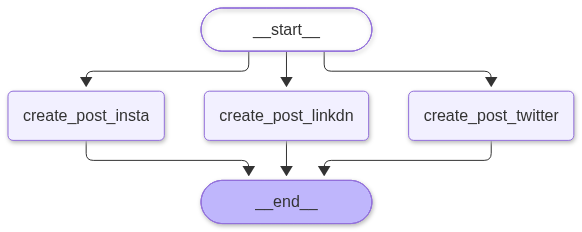

In [37]:
from IPython.display import Image,display

Image(parallel_graph.get_graph().draw_mermaid_png())

In [38]:
parallel_graph.invoke(
    {
    "topic" : "docker",
    "instagram": "",
    "twitter": "",
    "linkdn": "",
    }
)

{'topic': 'docker',
 'instagram': "🚀🐳 Yo, friends! Let's talk about Docker! If you haven't heard of this little miracle worker yet, it’s time to get on board! 🎉 \n\nImagine being able to package your app and all its dependencies into a neat little box (aka container) that you can run anywhere. Yup, that's Docker for ya! 🧑\u200d💻✨ \n\nNo more “it works on my machine” vibes 😩. Now you can chill and deploy straight to the cloud, your laptop, or even your friend’s grandma’s computer (okay, maybe not that last one 😂). \n\nWhether you're into coding, game dev, or just wanna flex your tech skills, Docker is a game-changer. It keeps your workflow clean and makes collaboration a breeze! 🌬️🤝\n\nSo, if you’re ready to level up your dev game, let’s get containerizing! 🐳💻 \n\nDrop your fav Docker tips and tricks in the comments! Let’s learn from each other! ❤️👇 #Docker #DevLife #TechTok #ContainerQueen #NoMoreMismatches",
 'twitter': '🌊🚀 Yo, fam! Let’s talk about Docker and why it’s an absolute gam

# Routing

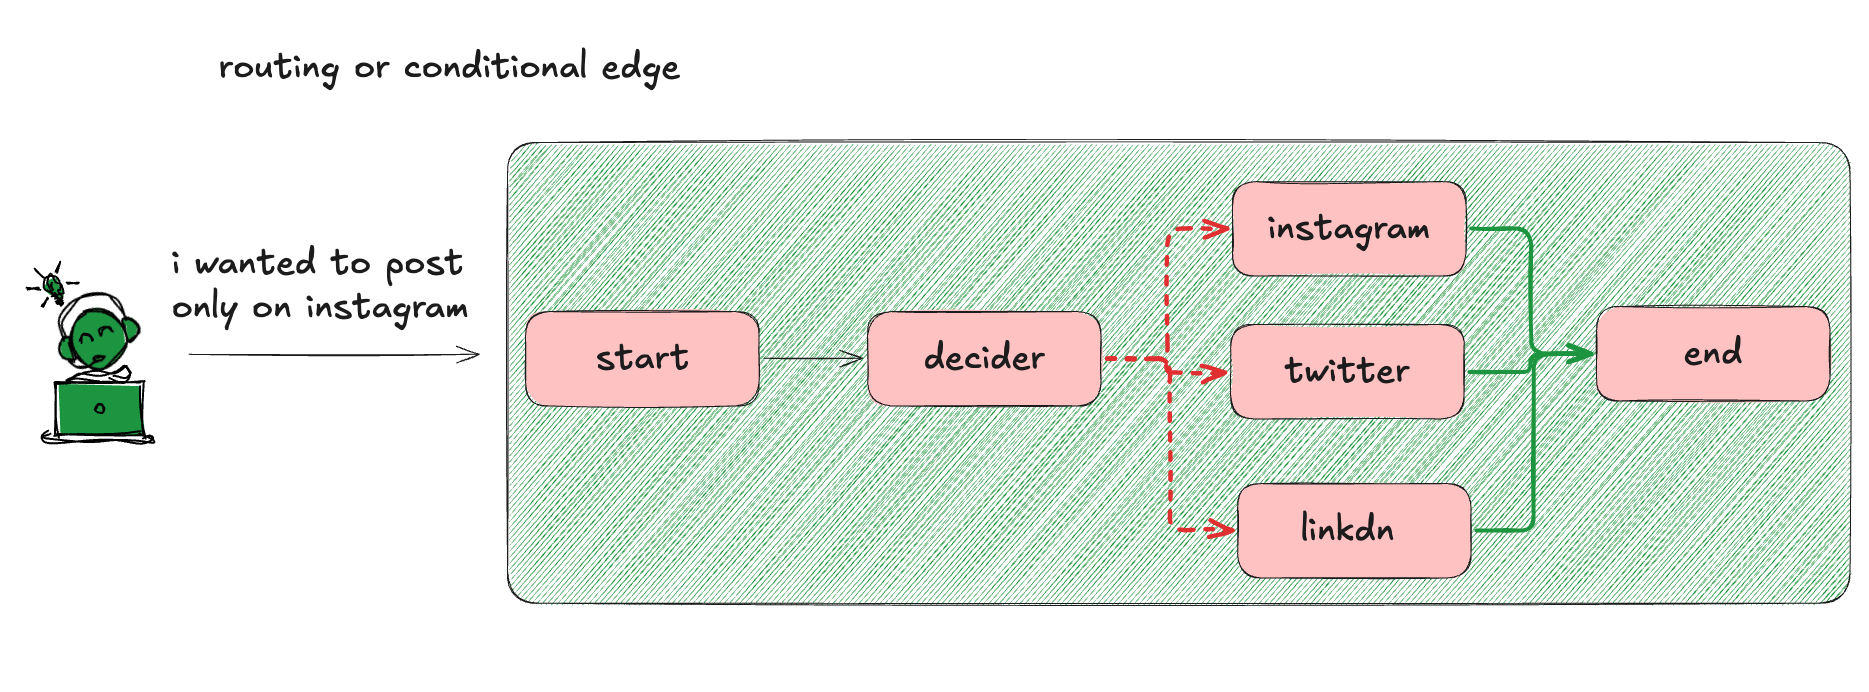

In [39]:
from pydantic import BaseModel, Field
from typing import Literal

class llm_schema(BaseModel):
    category: Literal['instagram','twitter','linkdn'] = Field(...,description="Category od post to generate")
    topic: str = Field(...,description="topic of post to generate")

In [40]:
llm_with_schema = llm.with_structured_output(llm_schema)

In [41]:
llm_with_schema.invoke("i wanted to generate a post for instagram about india")

llm_schema(category='instagram', topic='India')

In [42]:
from typing import TypedDict
class graph_schema(TypedDict):

    input: str
    topic: str
    post: str
    category: str 

    

In [56]:
# def decider_node(state: graph_schema) -> graph_schema:

#     # extract the input from the state

#     user_input = state['input']

#     # pass the user input put to llm  to decide the catogry of the post 

#     response = llm_with_schema.invoke(user_input)
#     category = response.category
#     topic = response.topic

#     return {"category": category, "topic": topic}


def decider_node(state: graph_schema) -> graph_schema:
    response = llm_with_schema.invoke(state["input"])
    category = state.get("category") or response.category

    return {"category": category, "topic": response.topic}

In [57]:
def create_post_insta(state: graph_schema) -> graph_schema:

    #extract the topic from state
    topic = state['topic']

    post = llm.invoke(f"write a post in instgram about {topic}. keep the tone casual and engaging and in genz in tone").content

    # update the state with generated the post
    state['post'] = post

    return {'post': post}

def create_post_twitter(state: graph_schema) -> graph_schema:

    #extract the topic from state
    topic = state['topic']

    post = llm.invoke(f"write a post in twitter about {topic}. keep the tone casual and engaging and in genz in tone").content

    # update the state with generated the post
    state['post'] = post

    return {'post': post}

def create_post_linkdn(state: graph_schema) -> graph_schema:

    #extract the topic from state
    topic = state['topic']

    post = llm.invoke(f"write a post in linkdn about {topic}. keep the tone casual and engaging and in genz in tone").content

    # update the state with generated the post
    state['post'] = post

    return {'post': post}


In [58]:
def condtion(state: graph_schema) -> graph_schema:

    category = state['category']

    if category == 'instagram':
        return 'create_post_insta'

    elif category == 'twitter':
        return 'create_post_twitter'
    
    elif category == 'linkdn':
        return 'create_post_linkdn'
    else:
        raise ValueError("Invalid category")

In [59]:
from langgraph.graph import StateGraph,START,END

graph = StateGraph(graph_schema)

graph.add_node("decider",decider_node)
graph.add_node("create_post_insta",create_post_insta)
graph.add_node("create_post_twitter",create_post_twitter)
graph.add_node("create_post_linkdn",create_post_linkdn)

graph.add_edge(START,"decider")

graph.add_conditional_edges("decider",condtion,
                            {
                               "create_post_insta":"create_post_insta", 
                               "create_post_twitter": "create_post_twitter",
                               "create_post_linkdn":"create_post_linkdn"
                            }
                    )

graph.add_edge("create_post_insta",END)
graph.add_edge("create_post_twitter",END)
graph.add_edge("create_post_linkdn",END)

route_graph = graph.compile()

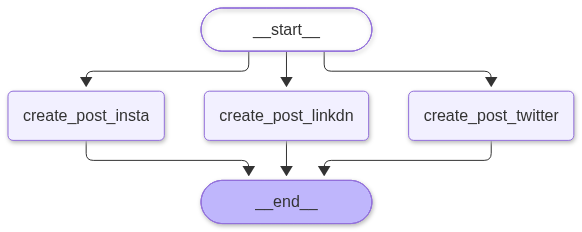

In [47]:
# earlier method
from IPython.display import Image,display

Image(parallel_graph.get_graph().draw_mermaid_png())

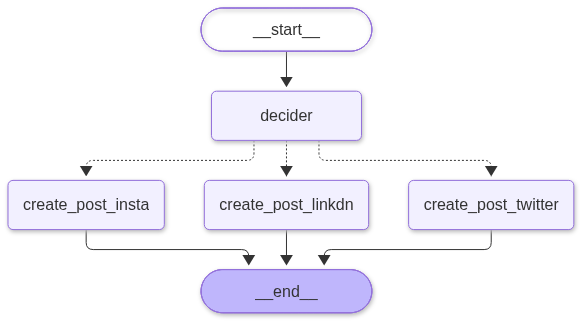

In [60]:
# NEW

from IPython.display import Image,display

Image(route_graph.get_graph().draw_mermaid_png())

In [61]:
route_graph.invoke(
    {
    "input" : "i wanted to generate post for instagram about devops jobs",
    "topic": "",
    "category": "",
    "post": "",
    }
)


{'input': 'i wanted to generate post for instagram about devops jobs',
 'topic': 'devops jobs',
 'post': "🌟 Hey fam! 🌟 Ever heard of DevOps? It's basically like the ultimate team-up of coding and managing systems! 🤖💻 If you’re into tech and love the idea of making things run smoothly behind the scenes, then this might just be your jam! 🚀✨\n\nDevOps jobs are where creativity meets collaboration – think of it like being the bridge between developers and operations. You get to solve real-world problems, automate repetitive tasks (bye-bye, boring stuff! 🙌), and help teams deliver awesome software way faster. \n\nPlus, the vibe in this field is super chill! Work remotely, flex your hours, and constantly learn new things. 📚🌍 And the best part? Companies are on the lookout for fresh talent, so there’s a ton of opportunities out there! 💸🔥\n\nSo, if you're ready to dive into the tech world, start exploring DevOps! You might just find your new passion. 🌈💖 \n\n#DevOps #TechJobs #FutureOfWork #Car

In [50]:
route_graph.invoke(
    {
    "input" : "i wanted to generate post for twitter about devops jobs",
    "topic": "",
    "category": "",
    "post": "",
    }
)

{'input': 'i wanted to generate post for twitter about devops jobs',
 'topic': 'devops jobs',
 'post': "🚀 Hey fam! 🌟 Are you ready to level up your career? DevOps jobs are the future, and they're 🔥🔥 right now! If you love coding, automating, and making all the tech magic happen, this is your sign! 💻✨\n\nWhether you’re a newbie or a seasoned pro, there’s a spot for you in this fast-paced world. Think of it as the ultimate team-up between devs and ops! 🤝🌈 \n\nSo, dust off that resume, brush up on your skills, and get ready to join the fun! Who's ready to build some cool stuff together? 🌍💪 #DevOps #TechJobs #CareerGoals #LevelUp",
 'category': 'twitter'}

In [51]:
route_graph.invoke(
    {
    "input" : "i wanted to generate post for whatsapp status about devops jobs",
    "topic": "",
    "category": "",
    "post": "",
    }
)

{'input': 'i wanted to generate post for whatsapp status about devops jobs',
 'topic': 'DevOps jobs',
 'post': "🌟 Hey fam! 🚀💻\n\nSo, let’s chat about DevOps jobs for a hot second! 🔥 If you’re vibin' with tech but also love the hustle of getting stuff DONE, then this might just be your next big move! 🌈✨\n\nDevOps isn’t just some buzzword—it’s where the magic happens! 💥 Imagine combining development and operations to create all sorts of dope solutions... and getting paid for it! 💰💥 You get to work with cool tools, automate all the things, and let’s be real, who doesn’t love a good CI/CD pipeline? 🙌\n\nPlus, the job market for DevOps pros is poppin' off! 💼📈 Companies are on the hunt for talent like yours—so if you’ve got those skills (or wanna learn), now’s your moment! 💪💖\n\nSo, who’s ready to dive into the world of cloud computing, containerization, and all that jazz? ☁️🙄 Let’s get that bag together! 💸✨\n\nDrop a 💖 if you’re interested, and let’s chat about how to jump into this wild ri

In [63]:
route_graph.invoke(
    {
    "input" : "i wanted to generate post for devops jobs",
    "topic": "",
    "category": "telegram",
    "post": "",
    }
)

ValueError: Invalid category

In [53]:
condtion({"category": "telegram"})

ValueError: Invalid category

In [62]:
route_graph.invoke({
    "input": "I want a post about DevOps jobs",
    "topic": "",
    "category": "whatsapp",
    "post": "",
})

ValueError: Invalid category